In [1]:
import pandas as pd
import sqlite3

In [2]:
conn = sqlite3.connect('../data/checking-logs.sqlite')

In [3]:
df = pd.read_sql("""
SELECT
    timestamp
FROM checker
WHERE uid LIKE 'user_%'
""", conn)

In [4]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

df['hour'] = df['timestamp'].dt.hour
df['weekday'] = df['timestamp'].dt.weekday  # Monday=0 … Sunday=6
df['date'] = df['timestamp'].dt.date


In [5]:
df['day_type'] = df['weekday'].apply(
    lambda x: 'Working day' if x < 5 else 'Weekend'
)


In [6]:
hourly_daily = (
    df
    .groupby(['day_type', 'date', 'hour'])
    .size()
    .reset_index(name='commits')
)


In [7]:
avg_commits = (
    hourly_daily
    .groupby(['day_type', 'hour'])['commits']
    .mean()
    .reset_index()
)


In [8]:
pivot = avg_commits.pivot(
    index='hour',
    columns='day_type',
    values='commits'
)
pivot = pivot.reindex(range(24))
pivot

day_type,Weekend,Working day
hour,,
0,2.000000,3.000000
1,6.000000,NaN
2,NaN,NaN
3,1.000000,2.000000
4,NaN,NaN
5,2.000000,7.500000
6,NaN,1.500000
7,4.000000,5.166667
8,7.000000,3.700000


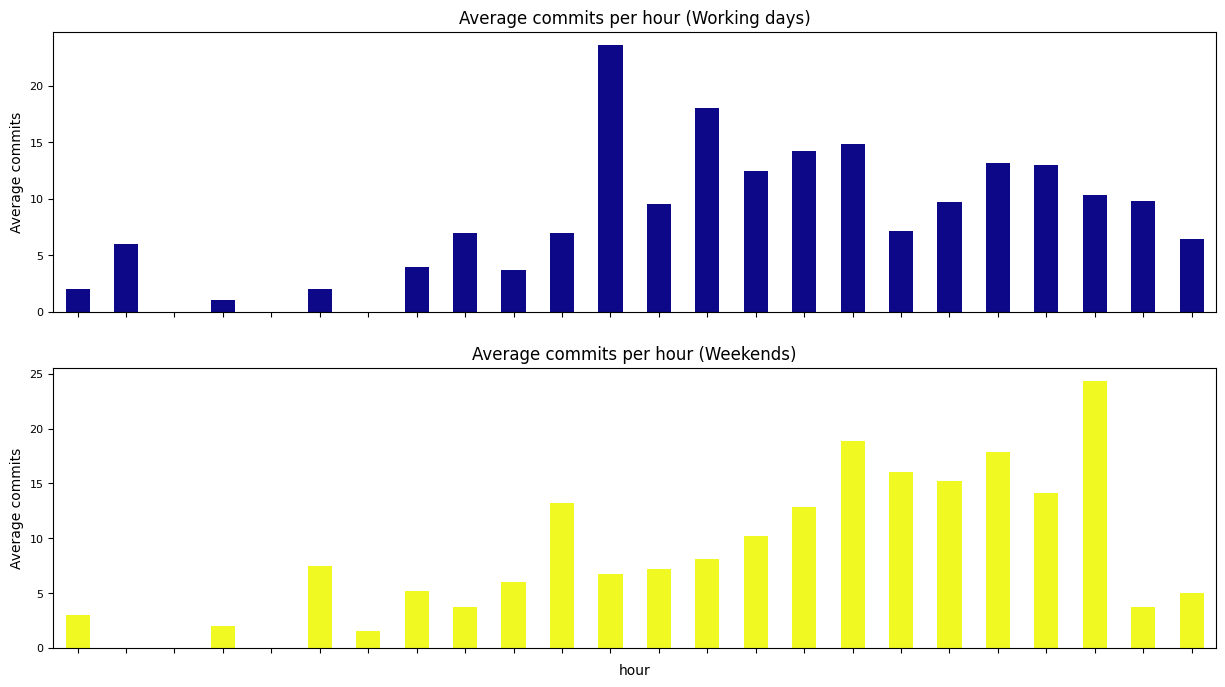

In [9]:
axes = pivot.plot(
    kind='bar',
    subplots=True,
    figsize=(15, 8),
    fontsize=8,
    colormap='plasma',
    sharex=True,
    legend=False,
    title=[
        'Average commits per hour (Working days)',
        'Average commits per hour (Weekends)'
    ]
)

for ax in axes:
    ax.set_ylabel('Average commits')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)


In [10]:
conn.close()

In [11]:
pivot.loc[[pivot['Weekend'].idxmax()]]

day_type,Weekend,Working day
hour,,
11,23.6,6.769231


In [12]:
pivot.loc[[pivot['Working day'].idxmax()]]

day_type,Weekend,Working day
hour,,
21,10.285714,24.333333


Is the dynamic different on working days and weekends?

Yes

The hour when the number of commits is largest during working days: 21

The hour when it is largest during the weekend: 11